In [10]:
from _Aplha_n_methods import Alpha_N_calc as an
from _Geometry_methods import Geometry_helper as gh
from _Prettyplt import PrettyPlot as pp

import openmc
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

import os
pp.makePretty(0.7)

In [13]:
#Setting geometry and materials
#Geometry
new_geom = True
date = "011026"
hour = 0
nr_steps = 48
timestep_units = 'h'

fuel_name = 'Fuel_CA_2'
blanket_name = 'Blanket_CA'


#Reactor geometry parameters
inner_fuel_r = 50
outer_fuel_r = 60
outer_moderater_r = 80
blanket_or = 100
    
#Control for readtor
inner_moderator_height = 80
    
materials = openmc.Materials.from_xml(f'{date} - materials/{fuel_name}_nr_{hour}_h.xml')
#materials = gh.create_materials(fuel_name)
geom, materials= gh.set_geom_fuel_shell(inner_fuel_r, outer_fuel_r, outer_moderater_r,
                                        with_blanket=True, blanket_or=blanket_or, 
                                        inner_moderator_height=inner_moderator_height, 
                                        materials=materials, fuel_name=fuel_name)

fuel = gh.get_material_by_name(fuel_name,materials)
blanket = gh.get_material_by_name(blanket_name,materials)

fuel.set_density('g/cm3',4.905)
blanket.set_density('g/cm3',4.626)

Materials defined: 
d2o
Air
Blanket_CA
Fuel_CA_2


In [3]:
#Print materials
def print_dep_material(material,threshold = 1e-9):
    total = 0
    new_total = 0
    print(f'\n{material.name}')
    print(f'density: {material.density}')
    #print(material.get_nuclide_atom_densities())
    
    for nuc_name,nuc_amount in material.get_nuclide_densities().items():
        total += nuc_amount.percent
    for nuc_name,nuc_amount in material.get_nuclide_densities().items():
        nuc_percent = nuc_amount.percent
        nuc_percent /= total
        new_total += nuc_percent
        if nuc_percent > threshold:
            print(f'{nuc_name}\t {nuc_percent:.3g}')
    print(f'total: {total:.5g}')
    print(f'new_total: {new_total:.5g}')
def check_fuel_from_ORNL(fuel,threshold = 1e-7):
    print('\n',fuel.name)
    nuclide_lib = {}
    total = 0
    for nuc,dens in fuel.get_nuclide_densities().items():
        symbol,Z,A = an.isolate_atomic_symbol(nuc)
        if symbol != 'F':
            #print(nuc,dens)
            mol = dens.percent
            total += mol
            if symbol in nuclide_lib:
                nuclide_lib[symbol]+=mol
            else:
                nuclide_lib[symbol]=mol
    
    for nuc in nuclide_lib:
        if nuclide_lib[nuc]/total*100 > threshold and nuc != 'F':
            print(f'{nuc}: {nuclide_lib[nuc]/total*100:.10g}')

print_dep_material(fuel)
print_dep_material(blanket)

check_fuel_from_ORNL(fuel)
check_fuel_from_ORNL(blanket)



Fuel_CA_2
density: 4.905
F19	 0.644
Li6	 2.6e-06
Li7	 0.26
U234	 4.3e-05
U235	 0.00481
U236	 2.21e-05
U238	 0.0912
total: 0.08001
new_total: 1

Blanket_CA
density: 4.626
F19	 0.655
Li6	 1.79e-05
Li7	 0.241
Th230	 2.07e-05
Th232	 0.103
total: 0.073034
new_total: 1

 Fuel_CA_2
Li: 72.99999995
Mo: 1.452025466e-07
Np: 1.966203655e-07
U: 26.99999897
Zr: 1.219411669e-07

 Blanket_CA
Li: 70
Th: 29.99999994


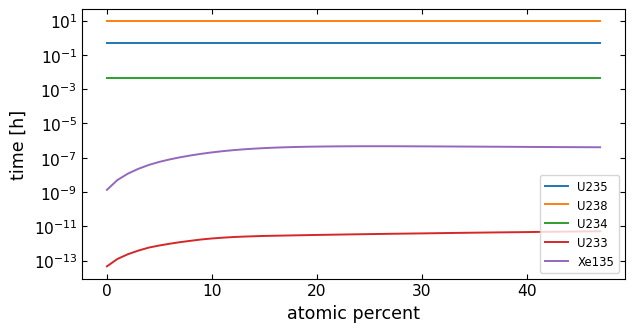

In [43]:
def check_isotopes_from_dep(material,isotopes):
    total = 0
    new_total = 0
    nuclide_lib = {}
    #print(f'\n{material.name}')
    #print(f'density: {material.density}')
    #print(material.get_nuclide_atom_densities())
    
    for nuc_name,nuc_amount in material.get_nuclide_densities().items():
        total += nuc_amount.percent
    for nuc_name,nuc_amount in material.get_nuclide_densities().items():
        nuc_percent = nuc_amount.percent
        nuc_percent /= total
        if nuc_name in isotopes:
            nuclide_lib[nuc_name]=nuc_percent*100
            #print(f'{nuc_name}: {nuclide_lib[nuc_name]*100:.10g}')
    return nuclide_lib
def get_isotopes_over_time(isotopes):
    isotopes_over_time = {}
    for isotope in isotopes:
        isotopes_over_time[isotope] = np.zeros(nr_steps)
        for hour in range(nr_steps):
            mats = openmc.Materials.from_xml(f'{date} - materials/{fuel_name}_nr_{hour}_h.xml')
            mat = gh.get_material_by_name(fuel_name,mats)
            
            isotope_lib = check_isotopes_from_dep(mat,isotope)
            
            isotopes_over_time[isotope][hour]= isotope_lib[isotope]
        

    return isotopes_over_time

#check_isotopes_from_dep(fuel,['Xe135','U235'])
isotopes = ['U235','U238','U234','U233','Xe135']
isotopes_over_time = get_isotopes_over_time(isotopes)

fig,ax = plt.subplots()

for isotope in isotopes:
    ax.plot(range(nr_steps),isotopes_over_time[isotope],label = isotope)
ax.set_ylabel('time [h]')
ax.set_xlabel('atomic percent')
ax.semilogy()
ax.legend()



 Fuel_CA_2
Writing SRIM file after 47 threshold tries
len target elements 100, #elements 100
SRModule done, length of data: 71 and 71


/openmc_venv/lib/python3.11/site-packages/openmc/mixin.py:70: IDWarning: Another Cell instance already exists with id=1.
  warn(msg, IDWarning)


Getting cross sections...
Making kernels and integrent...
setup done in 19.183696932999965 s
total_n_per_s: 3.535e+05 for Fuel_CA_2


 Blanket_CA
Writing SRIM file after 37 threshold tries
len target elements 100, #elements 100
SRModule done, length of data: 71 and 71
Getting cross sections...
Making kernels and integrent...
setup done in 22.755128240999966 s
total_n_per_s: 4.0498e+05 for Blanket_CA


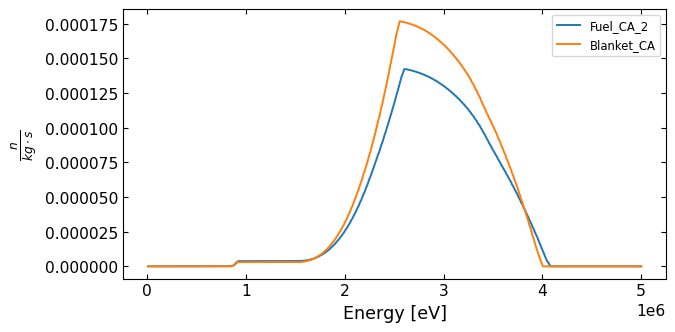

In [4]:
#Alpha-n from material
def shell_vol_calc(geom_or,geom_ir):
    volume=4/3*np.pi*(geom_or**3-geom_ir**3)
    return volume

def set_source(material,innr_r,outer_r):
    print(f'\n\n {material.name}')
    n_intensities,n_energies,n_per_s_per_kg = an.neutron_spectra_from_material(material,E_min=1e4,
                                                                               nr_points=1000,nr_energies=1000,
                                                                               new_file=True)
    
    n_intensities = np.clip(n_intensities,0,None)
    energy = openmc.stats.Tabular(n_energies, n_intensities)
    
    ax.plot(n_energies,n_intensities,label=material.name)
    
    material_vol = shell_vol_calc(outer_fuel_r,inner_fuel_r)
    material_mass = material.density*material_vol/1000
    total_n_per_s = n_per_s_per_kg*material_mass

    print(f'total_n_per_s: {total_n_per_s:.5g} for {material.name}')

    return openmc.IndependentSource(space=fuel_space, energy=energy,particle='neutron', strength=total_n_per_s)

inner_fuel_radius = geom.get_surfaces_by_name('fuel_inner')[0].bounding_box('-')[1][0]
outer_fuel_radius = geom.get_surfaces_by_name('fuel_outer')[0].bounding_box('-')[1][0]

inner_blanket_radius = geom.get_surfaces_by_name('blanket_inner')[0].bounding_box('-')[1][0]
outer_blanket_radius = geom.get_surfaces_by_name('blanket_outer')[0].bounding_box('-')[1][0]

fuel_space = openmc.stats.spherical_uniform(r_outer=outer_fuel_radius,r_inner=inner_fuel_radius)
blanket_space = openmc.stats.spherical_uniform(r_outer=outer_blanket_radius,r_inner=inner_blanket_radius)

fig,ax =plt.subplots()

ax.set_xlabel('Energy [eV]')
ax.set_ylabel(r'$\frac{n}{kg\cdot s}$')

fuel_src = set_source(fuel,inner_fuel_radius,outer_fuel_radius)
blanket_src = set_source(blanket,inner_blanket_radius,outer_blanket_radius)


ax.legend()






In [5]:
#Settings
settings = openmc.Settings()
settings.run_mode = 'eigenvalue'
settings.source =  [fuel_src,blanket_src]   # evt. + SF-kilde som separat source
settings.batches = 50
settings.inactive = 10
settings.particles = 5000 # is changed later

#Fixing Li6 at 900 K doesn't have a cross section 
settings.temperature = {
    'method': 'nearest',
    'tolerance': 1000}

model_eigen = openmc.Model(geometry=geom, materials=materials, settings=settings)



In [6]:
#Finding k_eff
#model_eigen.run()

In [7]:
keffs = np.zeros(48)
keffs_std = np.zeros(48)
for step in range(48):
    openmc.reset_auto_ids()
    os.system('rm s*h5')
    os.system('rm p*h5')
    os.system("rm model.xml")
    os.system("rm summary.h5")
    materials = openmc.Materials.from_xml(f'{date} - materials/{fuel_name}_nr_{step}_h.xml')
    #materials = gh.create_materials(fuel_name)
    geom, materials= gh.set_geom_fuel_shell(inner_fuel_r, outer_fuel_r, outer_moderater_r,
                                            with_blanket=True, blanket_or=blanket_or, 
                                            inner_moderator_height=inner_moderator_height, 
                                            materials=materials, fuel_name=fuel_name)
    
    fuel = gh.get_material_by_name(fuel_name,materials)
    blanket = gh.get_material_by_name(blanket_name,materials)
    
    model_eigen.geometry = geom
    model_eigen.materials = materials
    model_eigen.run()
    with openmc.StatePoint(f'statepoint.{settings.batches}.h5') as sp:
        keff = sp.keff
    
    keffs[step] = sp.keff.nominal_value
    keffs_std[step] = sp.keff.std_dev
    
    os.system(f'statepoint.{settings.batches}.h5')
    print(keffs[step])

#Saving results
data_to_file = np.column_stack((keffs,keffs_std))
np.savetxt(f'data/eigenvalue_{date}_time_{nr_steps}_{timestep_units}.csv',data_to_file,delimiter=",",
           header='keffs,keffs_std')

rm: cannot remove 'p*h5': No such file or directory
rm: cannot remove 'summary.h5': No such file or directory


Materials defined: 
d2o
Air
Blanket_CA
Fuel_CA_2
                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%

sh: 1: statepoint.50.h5: not found
rm: cannot remove 'p*h5': No such file or directory
rm: cannot remove 'summary.h5': No such file or directory


 Reading N14 from /root/nndc_hdf5/N14.h5
 Reading N15 from /root/nndc_hdf5/N15.h5
 Reading O17 from /root/nndc_hdf5/O17.h5
 Reading Ar36 from /root/nndc_hdf5/Ar36.h5
 Reading Ar38 from /root/nndc_hdf5/Ar38.h5
 Reading Ar40 from /root/nndc_hdf5/Ar40.h5
 Reading Pu236 from /root/nndc_hdf5/Pu236.h5
 Reading Am240 from /root/nndc_hdf5/Am240.h5
 Reading Am243 from /root/nndc_hdf5/Am243.h5
 Reading Cm240 from /root/nndc_hdf5/Cm240.h5
 Reading Cm241 from /root/nndc_hdf5/Cm241.h5
 Reading Cm242 from /root/nndc_hdf5/Cm242.h5
 Reading Cm243 from /root/nndc_hdf5/Cm243.h5
 Reading Cm245 from /root/nndc_hdf5/Cm245.h5
 Reading Cm246 from /root/nndc_hdf5/Cm246.h5
 Reading Cm247 from /root/nndc_hdf5/Cm247.h5
 Reading Bk245 from /root/nndc_hdf5/Bk245.h5
 Reading Bk246 from /root/nndc_hdf5/Bk246.h5
 Reading Bk247 from /root/nndc_hdf5/Bk247.h5
 Reading Bk248 from /root/nndc_hdf5/Bk248.h5
 Reading Cf246 from /root/nndc_hdf5/Cf246.h5
 Reading Cf249 from /root/nndc_hdf5/Cf249.h5
 Reading Cf250 from /root/nn

sh: 1: statepoint.50.h5: not found
rm: cannot remove 'p*h5': No such file or directory
rm: cannot remove 'summary.h5': No such file or directory


...

sh: 1: statepoint.50.h5: not found
rm: cannot remove 'p*h5': No such file or directory
rm: cannot remove 'summary.h5': No such file or directory


0.9967733378310316
Materials defined: 
d2o
Air
Blanket_CA
Fuel_CA_2
                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 ################

sh: 1: statepoint.50.h5: not found
rm: cannot remove 'p*h5': No such file or directory
rm: cannot remove 'summary.h5': No such file or directory


0.9957562852274501
Materials defined: 
d2o
Air
Blanket_CA
Fuel_CA_2
                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 ################

sh: 1: statepoint.50.h5: not found


In [8]:
print(keffs)

[1.00288873 0.99643559 0.99620531 0.99532414 0.99964619 0.9945539
 0.99490564 0.9971089  0.99397113 0.99434977 0.99655446 0.99722051
 0.996856   0.99623886 0.99439281 0.99126691 0.99698532 0.99267667
 0.99389927 0.99831286 0.99125111 0.99361072 0.99561153 0.99425989
 0.99271865 0.99863177 0.9949391  0.99597984 0.99718622 0.99702991
 0.9926369  0.99624882 0.99662608 0.99208999 0.99387243 0.99329271
 0.99643779 0.99805376 0.99111246 0.99413261 0.99659227 0.99388791
 0.99597468 0.99347804 0.99531315 0.99677334 0.99575629 0.99449254]
